In [139]:
import os
import platform
import subprocess
import pymc as pm
import arviz as az
import numpy as np
import scipy
import scipy.stats as stats
from scipy.optimize import minimize
import pandas as pd
import matplotlib.pyplot as plt
import numdifftools as nd
import pytensor


### Data Generation

In [140]:
rng = np.random.default_rng(seed=42)
x = rng.uniform(-2, 2, size=15)
e = rng.normal(loc=0, scale=0.25, size=15)
y = 1 + x + x ** 2 + e

### Plotting Data

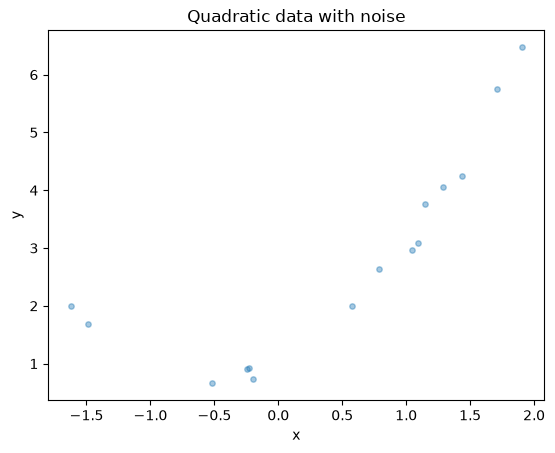

In [141]:
plt.scatter(x, y, alpha=0.4, s=15)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Quadratic data with noise")
plt.show()

In [142]:
with pm.Model() as model_linear:
    alpha1 = pm.Normal("alpha1", 0, 100)
    beta1 = pm.Normal("beta_1", 0, 100)
    sigma1 = pm.Exponential("sigma1", 1)
    mu1 = alpha1 + beta1 * x
    linear = pm.Normal("linear", mu=mu1, sigma=sigma1, observed=y)

    trace1 = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha1, beta_1, sigma1]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


In [143]:
with pm.Model() as model_quadratic:
    alpha2 = pm.Normal("alpha2", 0, 100)
    beta2_1 = pm.Normal("beta_2_1", 0, 100)
    beta2_2 = pm.Normal("beta_2_2", 0, 1)
    sigma2 = pm.Exponential("sigma2", 1)
    mu2 = alpha2 + beta2_1 * x + beta2_2 * x ** 2
    quadratic = pm.Normal("Quadratic", mu=mu2, sigma=sigma2, observed=y)

    trace2 = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha2, beta_2_1, beta_2_2, sigma2]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


In [144]:
with pm.Model() as model_fifth:
    alpha5 = pm.Normal("alpha5", 0, 100)
    beta5_1 = pm.Normal("beta_5_1", 0, 100)
    beta5_2 = pm.Normal("beta_5_2", 0, 100)
    beta5_3 = pm.Normal("beta_5_3", 0, 100)
    beta5_4 = pm.Normal("beta_5_4", 0, 100)
    beta5_5 = pm.Normal("beta_5_5", 0, 100)
    sigma5 = pm.Exponential("sigma5", 1)
    mu5 = (
        alpha5
        + beta5_1 * x
        + beta5_2 * x**2
        + beta5_3 * x**3
        + beta5_4 * x**4
        + beta5_5 * x**5
    )
    fifth = pm.Normal("Fifth degree", mu=mu5, sigma=sigma5, observed=y)

    trace5 = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha5, beta_5_1, beta_5_2, beta_5_3, beta_5_4, beta_5_5, sigma5]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4 seconds.
There were 174 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


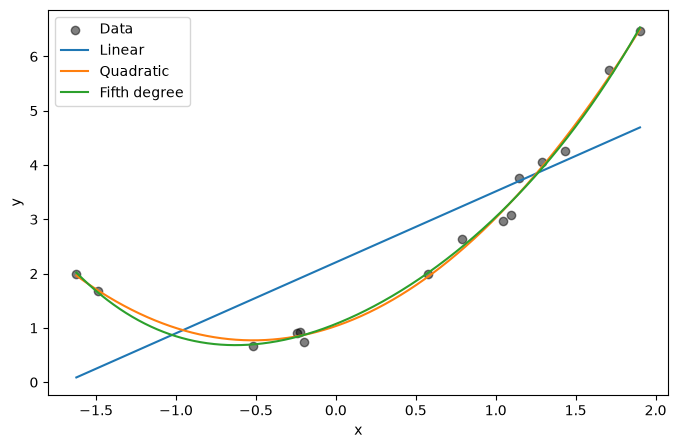

In [145]:
xx = np.linspace(x.min(), x.max(), 1000)

models = [
    (trace1, ["alpha1", "beta_1"], "Linear"),
    (trace2, ["alpha2", "beta_2_1", "beta_2_2"], "Quadratic"),
    (trace5, ["alpha5"] + [f"beta_5_{i}" for i in range(1, 6)], "Fifth degree"),
]

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color="black", alpha=0.5, label="Data")

for trace, names, label in models:
    coefficients = [float(trace.posterior[name].mean()) for name in names]
    yy = np.polynomial.polynomial.polyval(xx, coefficients)
    plt.plot(xx, yy, label=label)

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

### Testing with Unobserved Data

In [146]:
x_ofs = rng.uniform(-2, 2, size=200)
e_ofs = rng.normal(loc=0, scale=0.25, size=200)
y_ofs = 1 + 2 * x_ofs + x_ofs**2 + e_ofs

#### Linear model

In [147]:
posterior = trace1.posterior
mu_linear = (
    posterior["alpha1"].values[..., None]
    + posterior["beta_1"].values[..., None] * x_ofs
)

mse_linear = np.mean((np.asarray(y_ofs) - mu_linear.mean(axis=(0, 1))) ** 2)

In [148]:
posterior = trace2.posterior
mu_quadratic = (
    posterior["alpha2"].values[..., None]
    + posterior["beta_2_1"].values[..., None] * x_ofs
    + posterior["beta_2_2"].values[..., None] * x_ofs**2
)

mse_quadratic = np.mean((np.asarray(y_ofs) - mu_quadratic.mean(axis=(0, 1))) ** 2)

In [149]:
posterior = trace5.posterior
mu_fifth = (
    posterior["alpha5"].values[..., None]
    + posterior["beta_5_1"].values[..., None] * x_ofs
    + posterior["beta_5_2"].values[..., None] * x_ofs**2
    + posterior["beta_5_3"].values[..., None] * x_ofs**3
    + posterior["beta_5_4"].values[..., None] * x_ofs**4
    + posterior["beta_5_5"].values[..., None] * x_ofs**5
)

mse_fifth = np.mean((np.asarray(y_ofs) - mu_fifth.mean(axis=(0, 1))) ** 2)

In [150]:
print(f"Liner MSE:{mse_linear}, Quadratic MSE:{mse_quadratic}, Fifth MSE:{mse_fifth}")

Liner MSE:1.8457044422842626, Quadratic MSE:1.3224006430544706, Fifth MSE:1.3372255036904588
